# Code für Vorlesungsinhalte 03_Bias

In [ ]:
# Install imbalanced-learn if not already installed
# !pip install imbalanced-learn

In [1]:
# Import der nötigen Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [14]:
# Schritt 1: Dummy-Daten erzeugen (mit Imbalance)
X, y = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0,
                           n_clusters_per_class=1, weights=[0.85, 0.15], flip_y=0, random_state=1)

df_original = pd.DataFrame(X, columns=["Feature1", "Feature2"])
df_original["Target"] = y

df_original.sample(10)

# Anzeigen der Menge von Instanzen pro Target Class
# df_original["Target"].value_counts()

,count
Target,
0,425
1,75


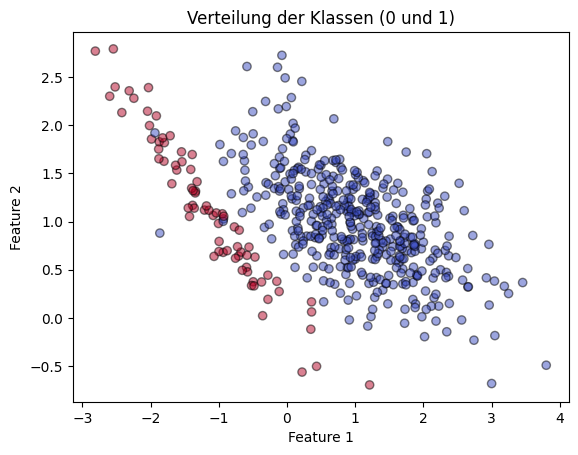

In [10]:
# Scatterplot der Daten
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor='k', alpha=0.5)
plt.title("Verteilung der Klassen (0 und 1)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Over- und Undersampling

In [16]:
# Schritt 2: Oversampling anwenden
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X, y)
df_over = pd.DataFrame(X_over, columns=["Feature1", "Feature2"])
df_over["Target"] = y_over

# Schritt 3: Undersampling anwenden
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X, y)
df_under = pd.DataFrame(X_under, columns=["Feature1", "Feature2"])
df_under["Target"] = y_under


# Anzeigen der Menge von Instanzen pro Target Class
df_over["Target"].value_counts()
# df_under["Target"].value_counts()

,count
Target,
0,75
1,75


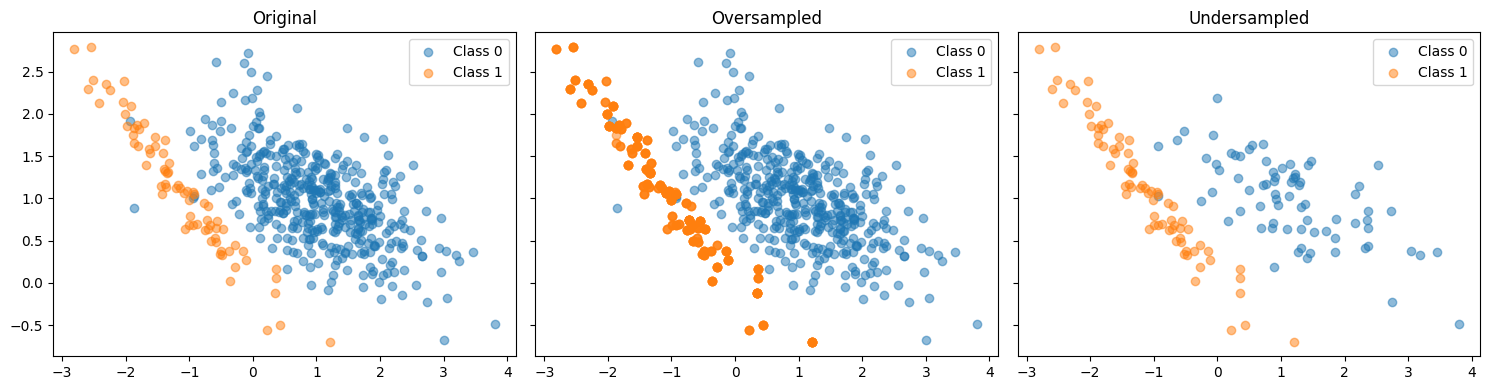

In [17]:
# Visualisierung vorbereiten
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

# Original
axes[0].scatter(df_original[df_original.Target==0]["Feature1"], df_original[df_original.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[0].scatter(df_original[df_original.Target==1]["Feature1"], df_original[df_original.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[0].set_title("Original")
axes[0].legend()

# Oversampled
axes[1].scatter(df_over[df_over.Target==0]["Feature1"], df_over[df_over.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[1].scatter(df_over[df_over.Target==1]["Feature1"], df_over[df_over.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[1].set_title("Oversampled")
axes[1].legend()

# Undersampled
axes[2].scatter(df_under[df_under.Target==0]["Feature1"], df_under[df_under.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[2].scatter(df_under[df_under.Target==1]["Feature1"], df_under[df_under.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[2].set_title("Undersampled")
axes[2].legend()

plt.tight_layout()
plt.show()

# SMOTE

In [19]:
# Schritt 4: SMOTE anwenden
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)
df_smote = pd.DataFrame(X_smote, columns=["Feature1", "Feature2"])
df_smote["Target"] = y_smote

# Anzeigen der Menge von Instanzen pro Target Class
df_smote["Target"].value_counts()

,count
Target,
0,425
1,425


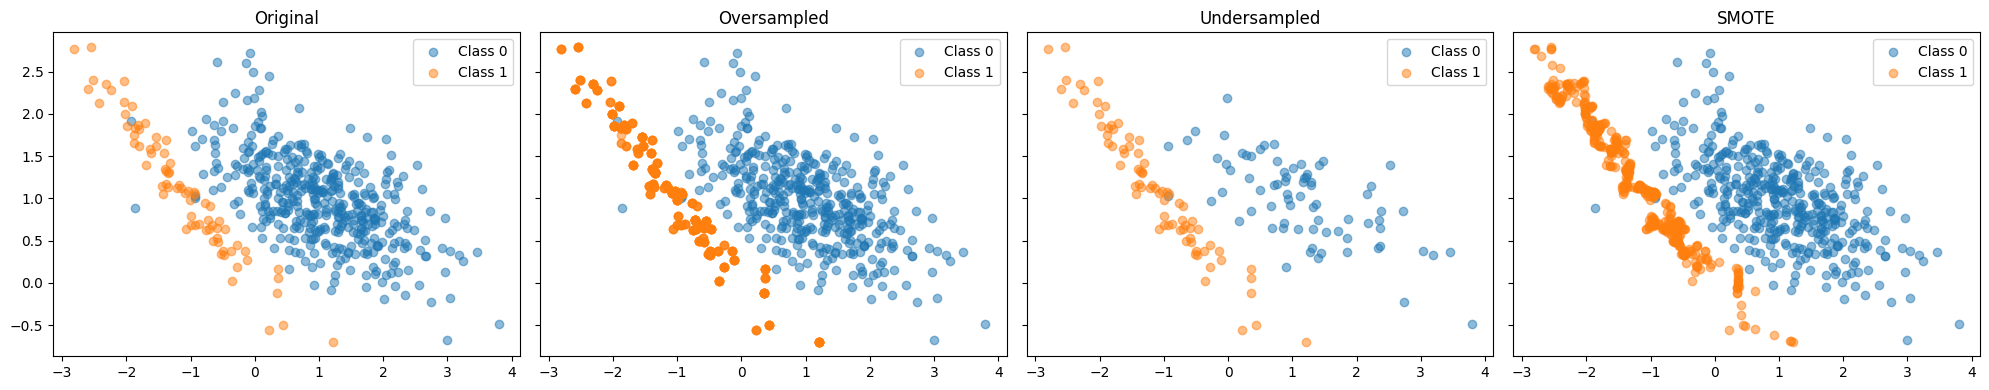

In [20]:
# Visualisierung aller Varianten
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True, sharey=True)

# Original
axes[0].scatter(df_original[df_original.Target==0]["Feature1"], df_original[df_original.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[0].scatter(df_original[df_original.Target==1]["Feature1"], df_original[df_original.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[0].set_title("Original")
axes[0].legend()

# Oversampled
axes[1].scatter(df_over[df_over.Target==0]["Feature1"], df_over[df_over.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[1].scatter(df_over[df_over.Target==1]["Feature1"], df_over[df_over.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[1].set_title("Oversampled")
axes[1].legend()

# Undersampled
axes[2].scatter(df_under[df_under.Target==0]["Feature1"], df_under[df_under.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[2].scatter(df_under[df_under.Target==1]["Feature1"], df_under[df_under.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[2].set_title("Undersampled")
axes[2].legend()

# SMOTE
axes[3].scatter(df_smote[df_smote.Target==0]["Feature1"], df_smote[df_smote.Target==0]["Feature2"], alpha=0.5, label="Class 0")
axes[3].scatter(df_smote[df_smote.Target==1]["Feature1"], df_smote[df_smote.Target==1]["Feature2"], alpha=0.5, label="Class 1")
axes[3].set_title("SMOTE")
axes[3].legend()

plt.tight_layout()
plt.show()

# Stratified Sampling

In [29]:
# Kontrollausgabe der Klassenverteilung
print("Originale Verteilung:")
print(df_original["Target"].value_counts(normalize=True))  # normalize gibt die prozentuale Verteilung an

Originale Verteilung:
Target
0    0.85
1    0.15
Name: proportion, dtype: float64


In [30]:
# Ohne Stratified Sampling
X = df_original[["Feature1", "Feature2"]]
y = df_original["Target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) # automatisierter Train/Test Split nach 30%/70%

print("\nVerteilung im Trainingsdatensatz (ohne Stratified):")
print(y_train.value_counts(normalize=True))

print("\nVerteilung im Testdatensatz (ohne Stratified):")
print(y_test.value_counts(normalize=True))


Verteilung im Trainingsdatensatz (ohne Stratified):
Target
0    0.857143
1    0.142857
Name: proportion, dtype: float64

Verteilung im Testdatensatz (ohne Stratified):
Target
0    0.833333
1    0.166667
Name: proportion, dtype: float64


In [31]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("\nVerteilung im Trainingsdatensatz (ohne Stratified):")
print(y_train.value_counts(normalize=True))

print("\nVerteilung im Testset (mit Stratified):")
print(y_test_s.value_counts(normalize=True))


Verteilung im Trainingsdatensatz (ohne Stratified):
Target
0    0.857143
1    0.142857
Name: proportion, dtype: float64

Verteilung im Testset (mit Stratified):
Target
0    0.853333
1    0.146667
Name: proportion, dtype: float64


# Cost-Sensitive Learning

In [33]:
# Weitere Bibliotheken importieren --> eigentlich oben hinzufügen
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

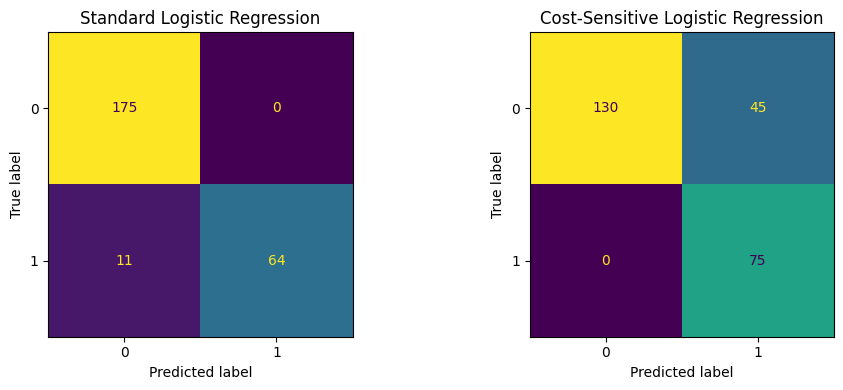

In [66]:
# Dummy-Daten mit Imbalance: 70% Klasse 0, 30% Klasse 1
X, y = make_classification(n_samples=1000, n_features=2, n_informative=2,
                           n_redundant=0, n_clusters_per_class=1,
                           weights=[0.7, 0.3], flip_y=0, random_state=42)

# Aufteilen in Trainings- und Testdaten
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# Modell 1: Ohne Kostenanpassung (Standard)
model_std = LogisticRegression(solver='liblinear')
model_std.fit(X_train, y_train)
y_pred_std = model_std.predict(X_test)

# Modell 2: Cost-Sensitive (mit class_weight)
# model_cost = LogisticRegression(class_weight='balanced', solver='liblinear')
model_cost = LogisticRegression(class_weight={0:1, 1:20})  # eigene Gewichtung definieren --> Fehler bei wahrer Klasse 1 wird 10x so stark bestraft wie Fehler bei wahrer Klasse 0

model_cost.fit(X_train, y_train)
y_pred_cost = model_cost.predict(X_test)

# Visualisierung der Konfusionsmatrizen
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_std, ax=ax[0], colorbar=False)
ax[0].set_title("Standard Logistic Regression")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cost, ax=ax[1], colorbar=False)
ax[1].set_title("Cost-Sensitive Logistic Regression")

plt.tight_layout()
plt.show()

In [67]:
# Definition der Gesamtkosten anhand einer eigens definierten Kostenmatrix

# Deine Kostenmatrix:
#            PRED 0  PRED 1
# TRUE 0  ->   0       1
# TRUE 1  ->  10       0

COST_MATRIX = {
    (0, 0): 0,   # True Negative
    (0, 1): 1,   # False Positive
    (1, 0): 15,  # False Negative (besonders teuer)
    (1, 1): 0    # True Positive
}

# Funktion zur Berechnung der Gesamtkosten
def calculate_total_cost(y_true, y_pred, cost_matrix):
    total_cost = 0
    for yt, yp in zip(y_true, y_pred):
        total_cost += cost_matrix[(yt, yp)]  # Abfrage der Kosten der Kombination auf Wahrheit und Vorhersage
    return total_cost

In [68]:
#

cost_std = calculate_total_cost(y_test, y_pred_std, COST_MATRIX)
cost_cost = calculate_total_cost(y_test, y_pred_cost, COST_MATRIX)

print(f"Gesamtkosten – Standardmodell:       {cost_std}")
print(f"Gesamtkosten – Cost-Sensitive-Modell: {cost_cost}")

Gesamtkosten – Standardmodell:       165
Gesamtkosten – Cost-Sensitive-Modell: 45
